# Replication of the textbook experiment and first Heston calibration to SPY options
**TFG (BSc in Economics, Universitat Pompeu Fabra)** · Carles Aliern Fons · supervisor: Elisa Alòs

Steps: (1) download an option chain, (2) estimate the forward by put-call parity and keep out-of-the-money options,
(3) calibrate Heston by least squares (error measured in implied-volatility units), (4) compare model vs market,
(5) compare with the decomposition formula and conditional Monte Carlo at the calibrated parameters.

Requires `heston_tfg.py` and `heston_experiment.py` in the same folder, and `pip install yfinance`.

Section 1 downloads the SPY option chain of the day on which the notebook is run and saves a copy (`SPY_chain_YYYY-MM-DD.csv`). The results shown here were obtained on 8 October 2026 with the close of 7 October; that snapshot is saved as `SPY_chain_2026-10-08.csv`. Running the notebook on another day downloads other quotes and gives different numbers.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, datetime as dt
from heston_tfg import *
from heston_experiment import heston_decomposition, heston_mc_conditional

TICKER = "SPY"
R = fetch_risk_free(default=0.04)   # 13-week T-bill yield (^IRX); 4% if it cannot be downloaded
print(f"risk-free rate used: {R:.4f}")

risk-free rate used: 0.0404


## 0. Replication of the book experiment
$S_0=K=100,\ T=1,\ r=0,\ \kappa=1,\ \theta=0.09,\ \sigma_0^2=0.04,\ \nu=0.3,\ \rho=-0.5$.
Book: analytical 9.2264, decomposition 9.2165, conditional Milstein 9.2270 / 9.2327 (≈79 s with 5,000 paths and 1,000 steps).

In [2]:
import time
from heston_experiment import heston_call, bs_call, implied_vol
S0, K0, T0, r0 = 100.0, 100.0, 1.0, 0.0
kap, th, v00, nu0, rho0 = 1.0, 0.09, 0.04, 0.3, -0.5
rows = []
t = time.perf_counter(); a = heston_call(S0, K0, v00, r0, T0, kap, th, nu0, rho0); rows.append(("Analytical (Fourier)", a, time.perf_counter() - t, "9.2264"))
t = time.perf_counter(); d = heston_decomposition(S0, K0, v00, r0, T0, kap, th, nu0, rho0); rows.append(("Decomposition", d, time.perf_counter() - t, "9.2165"))
t = time.perf_counter(); m, se = heston_mc_conditional(S0, K0, v00, r0, T0, kap, th, nu0, rho0, m=1000, n=5000, seed=1); rows.append(("Cond. MC Milstein (5k paths, 1000 steps)", m, time.perf_counter() - t, "9.2270"))
t = time.perf_counter(); m2, se2 = heston_mc_conditional(S0, K0, v00, r0, T0, kap, th, nu0, rho0, m=250, n=200_000, seed=2); rows.append(("Cond. MC Milstein (200k paths, 250 steps)", m2, time.perf_counter() - t, "-"))
print(f"MC standard errors: {se:.4f} (5k paths), {se2:.4f} (200k paths)")
pd.DataFrame(rows, columns=["method", "price", "seconds", "book"]).round(4)

MC standard errors: 0.0609 (5k paths), 0.0098 (200k paths)


,method,price,seconds,book
0,Analytical (Fourier),9.2264,0.0013,9.2264
1,Decomposition,9.2165,0.0003,9.2165
2,"Cond. MC Milstein (5k paths, 1000 steps)",9.1119,0.0648,9.2270
3,"Cond. MC Milstein (200k paths, 250 steps)",9.2198,1.9546,-


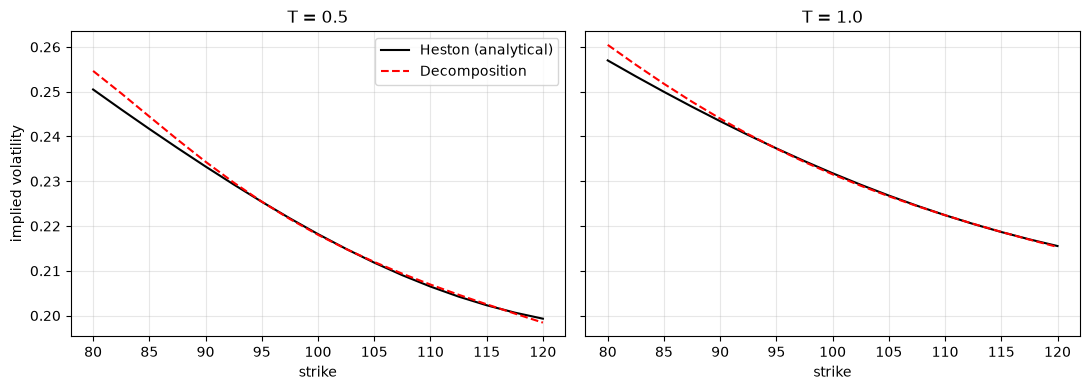

In [3]:
strikes = np.arange(80.0, 120.1, 2.5)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, TT in zip(axes, (0.5, 1.0)):
    iv_a = [implied_vol(heston_call(S0, k, v00, r0, TT, kap, th, nu0, rho0), S0, k, r0, TT) for k in strikes]
    iv_d = [implied_vol(heston_decomposition(S0, k, v00, r0, TT, kap, th, nu0, rho0), S0, k, r0, TT) for k in strikes]
    ax.plot(strikes, iv_a, "k-", label="Heston (analytical)"); ax.plot(strikes, iv_d, "r--", label="Decomposition")
    ax.set_title(f"T = {TT}"); ax.set_xlabel("strike"); ax.grid(alpha=.3)
axes[0].set_ylabel("implied volatility"); axes[0].legend()
plt.tight_layout(); plt.savefig("book_implied_vol.png", dpi=150); plt.show()

## 1. Real data

In [4]:
USING_SYNTHETIC = False
try:
    spot, raw = fetch_yfinance_chain(TICKER, min_days=14, max_days=400, max_expiries=8)
    raw.to_csv(f"{TICKER}_chain_{dt.date.today()}.csv", index=False)   # keep a snapshot: market data changes every day
    print(f"{TICKER} spot = {spot:.2f}, {len(raw)} quotes, {raw.expiry.nunique()} maturities (saved to CSV)")
    chain = build_clean_chain(raw, spot, r=R)
    print("cleaning (number of options removed at each step):", chain.attrs.get("cleaning"))
except Exception as e:
    print("!! Could not download real data:", repr(e)[:200])
    print("!! Using a SYNTHETIC market (known Heston parameters) just to test the code.")
    USING_SYNTHETIC = True
    TRUE = (2.0, 0.05, 0.6, -0.7, 0.03)
    chain = synthetic_chain(TRUE, noise_vol=0.002)
print(len(chain), "options kept after cleaning; price source:", chain["src"].value_counts().to_dict())
if (chain["src"] == "last").any():
    print("note: 'last' = last traded price (no live bid/ask, e.g. market closed) -> noisier, possibly non-synchronous")
chain.groupby("T").agg(F=("F", "first"), n=("K", "size"), iv_min=("iv", "min"), iv_max=("iv", "max")).round(4)

SPY spot = 777.22, 2651 quotes, 8 maturities (saved to CSV)


cleaning (number of options removed at each step): {'options_before': 884, 'last_price_quotes': 0, 'low_vega': 0, 'iv_outliers': 12, 'options_after': 872}
872 options kept after cleaning; price source: {'mid': 872}


,F,n,iv_min,iv_max
T,,,,
0.043836,778.7147,113,0.0945,0.4112
0.082192,780.0050,85,0.1086,0.3178
0.147945,781.9025,165,0.1091,0.3189
0.232877,782.9927,184,0.1134,0.2924
0.312329,785.7496,129,0.1167,0.2753
0.446575,789.9572,62,0.1203,0.2597
0.728767,797.7290,112,0.1288,0.2453
0.980822,805.6502,22,0.1475,0.2352


Market smiles (implied volatility vs log-moneyness), one curve per maturity:

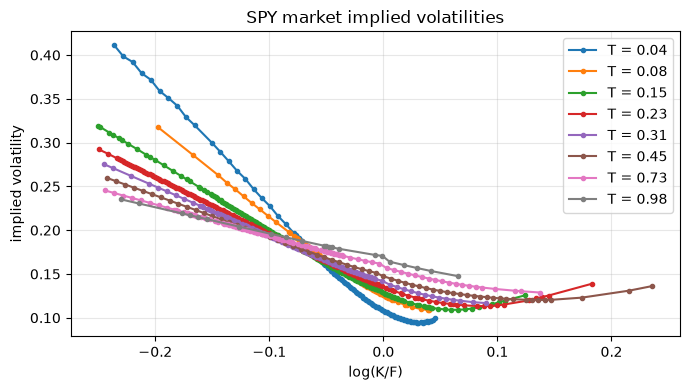

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
for T, g in chain.groupby("T"):
    ax.plot(np.log(g.K / g.F), g.iv, "o-", ms=3, label=f"T = {T:.2f}")
ax.set_xlabel("log(K/F)"); ax.set_ylabel("implied volatility"); ax.grid(alpha=.3); ax.legend()
ax.set_title(f"{TICKER} market implied volatilities" + ("  [SYNTHETIC]" if USING_SYNTHETIC else ""))
plt.tight_layout(); plt.savefig("market_smiles.png", dpi=150); plt.show()

## 2. Calibration
Minimise $\sum_i \big((P^{Heston}_i-P^{mkt}_i)/\text{vega}_i\big)^2$, which is approximately the squared implied-vol error.
Three starting points are used because the objective is non-convex (as the chapter warns).

In [6]:
params, fit, rmse = calibrate(chain, R)
print("\nCalibrated parameters:", {k: round(v, 4) for k, v in params.items()})
print(f"RMSE in implied vol: {rmse*100:.2f} vol points")
print(f"Feller 2*kappa*theta - nu^2 = {feller(params):.4f}  ({'satisfied' if feller(params) > 0 else 'violated'})")
print(f"Long-run vol sqrt(theta) = {np.sqrt(params['theta']):.3f},  initial vol sqrt(v0) = {np.sqrt(params['v0']):.3f}")

[fourier] start [ 2.     0.04   0.5   -0.7    0.169] -> cost 0.023283  params [ 7.1167  0.0417  1.575  -0.6287  0.0108]


[fourier] start [ 1.     0.06   0.3   -0.5    0.169] -> cost 0.023283  params [ 7.1164  0.0417  1.575  -0.6287  0.0108]


[fourier] start [ 5.     0.04   1.    -0.8    0.169] -> cost 0.023283  params [ 7.1163  0.0417  1.575  -0.6287  0.0108]



Calibrated parameters: {'kappa': 7.1163, 'theta': 0.0417, 'nu': 1.575, 'rho': -0.6287, 'v0': 0.0108}
RMSE in implied vol: 0.99 vol points
Feller 2*kappa*theta - nu^2 = -1.8867  (violated)
Long-run vol sqrt(theta) = 0.204,  initial vol sqrt(v0) = 0.104


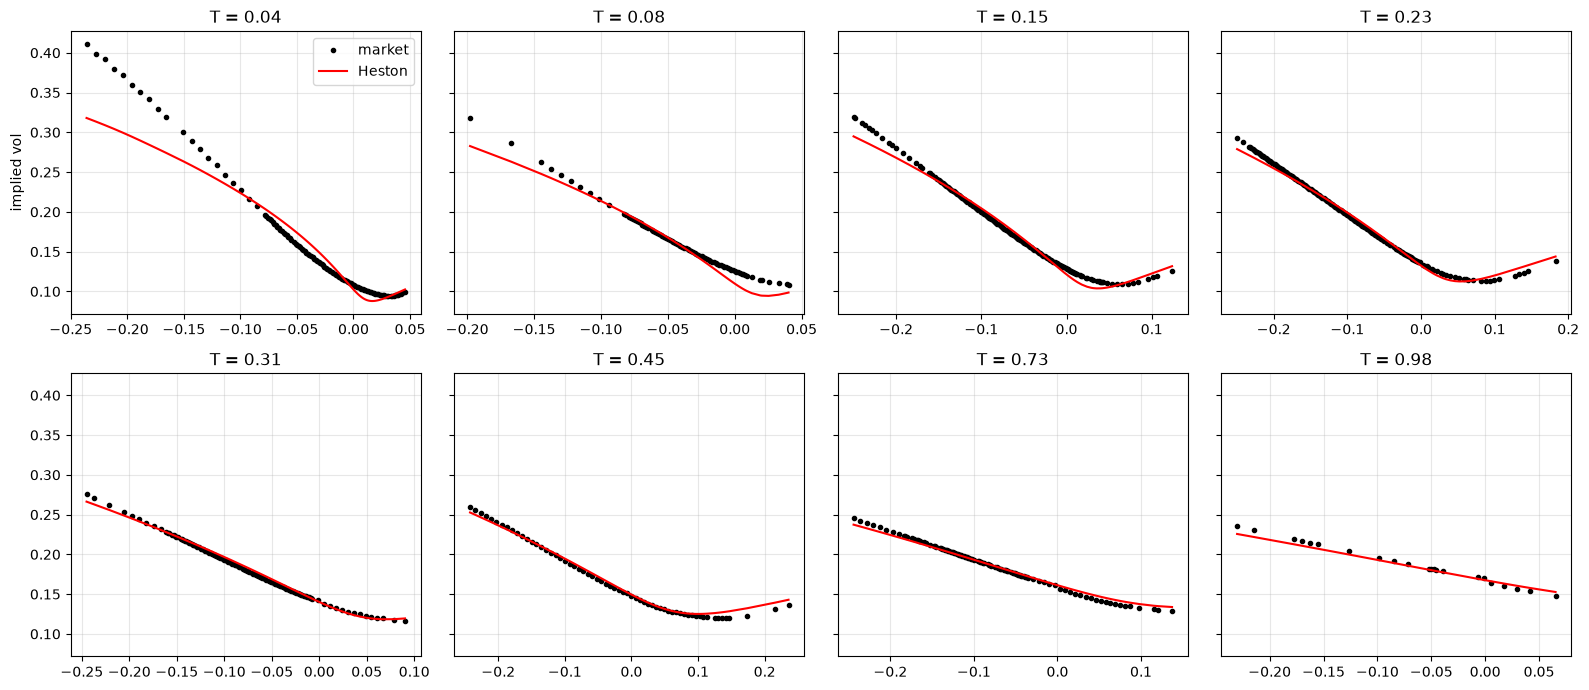

In [7]:
Ts = sorted(fit["T"].unique()); n = len(Ts)
fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(4 * ((n + 1) // 2), 7), sharey=True); axes = axes.ravel()
for ax, T in zip(axes, Ts):
    g = fit[fit["T"] == T]; x = np.log(g.K / g.F)
    ax.plot(x, g.iv, "ko", ms=3, label="market"); ax.plot(x, g.model_iv, "r-", label="Heston")
    ax.set_title(f"T = {T:.2f}"); ax.grid(alpha=.3)
axes[0].legend(); axes[0].set_ylabel("implied vol")
for ax in axes[n:]: ax.axis("off")
plt.tight_layout(); plt.savefig("calibration_fit.png", dpi=150); plt.show()

## 3. Decomposition formula and conditional Monte Carlo at the calibrated parameters

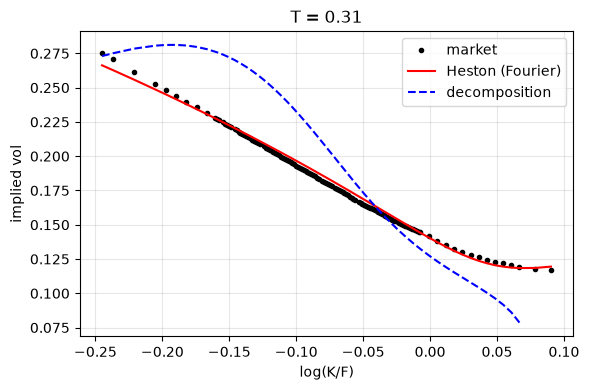

ATM call (K=785.0, T=0.31):  Fourier 24.6876 | decomposition 22.4445 | conditional MC 27.4825 +- 0.0315


In [8]:
p = params; T = Ts[len(Ts)//2]; g = fit[fit["T"] == T]; F = g.F.iloc[0]
Ks = g.K.values
heston = heston_call_fwd(F, Ks, T, R, p["kappa"], p["theta"], p["nu"], p["rho"], p["v0"])
decomp = np.array([np.exp(-R*T) * heston_decomposition(F, K, p["v0"], 0.0, T, p["kappa"], p["theta"], p["nu"], p["rho"]) for K in Ks])
iv_h = [implied_vol_fwd(c, F, K, T, R) for c, K in zip(heston, Ks)]
iv_d = [implied_vol_fwd(c, F, K, T, R) for c, K in zip(decomp, Ks)]
plt.figure(figsize=(6, 4)); x = np.log(Ks / F)
plt.plot(x, g.iv, "ko", ms=3, label="market"); plt.plot(x, iv_h, "r-", label="Heston (Fourier)"); plt.plot(x, iv_d, "b--", label="decomposition")
plt.xlabel("log(K/F)"); plt.ylabel("implied vol"); plt.title(f"T = {T:.2f}"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig("decomposition_vs_heston.png", dpi=150); plt.show()

K_atm = Ks[np.argmin(abs(Ks - F))]
mc, se = heston_mc_conditional(F, K_atm, p["v0"], 0.0, T, p["kappa"], p["theta"], p["nu"], p["rho"], m=250, n=100_000, seed=1)
print(f"ATM call (K={K_atm:.1f}, T={T:.2f}):  Fourier {heston[np.argmin(abs(Ks-F))]:.4f} | decomposition {decomp[np.argmin(abs(Ks-F))]:.4f} | "
      f"conditional MC {np.exp(-R*T)*mc:.4f} +- {np.exp(-R*T)*se:.4f}")

## 4. Findings (SPY, close of 7 October 2026)
- **Book replication:** analytical 9.2264 and decomposition 9.2165, exactly as in the book. Conditional Monte Carlo: 9.11 ± 0.06 with 5,000 paths and 9.220 ± 0.010 with 200,000 paths, consistent with the book's 9.2270 / 9.2327 within Monte Carlo error. Vectorised code: about 0.1 s instead of 79 s.
- **Calibration** (872 options, 8 maturities from 16 days to 1 year): $\kappa \approx 7.1$, $\theta \approx 0.042$, $\nu \approx 1.58$, $\rho \approx -0.63$, $\sigma_0 \approx 10\%$. RMSE ≈ 1.0 vol point. The Feller condition is strongly violated ($2\kappa\theta \approx 0.59 < \nu^2 \approx 2.48$).
- **Fit by maturity:** good from one month on. At the shortest maturity Heston cannot reach the implied volatility of far out-of-the-money puts (Section 2.6.2).
- **At the calibrated parameters,** for the ATM 4-month call: Fourier 24.69, decomposition 22.44 (−9%), conditional Monte Carlo with reflection 27.48 (+11%). Both the approximation and the Monte Carlo scheme deteriorate when $\nu$ is large and Feller is violated.
- **Parameter sensitivity:** removing 12 outlying quotes changed $\kappa$ from 5.8 to 7.1. This is the identification problem mentioned in the chapter.